# Check evaluation dataset for each eval_st_training_dataset_id

- Consistency checks between .h5 and .h5ad
- Visualization utilities:
  - patch grids
  - single patch view
  - nuclei mask overlay (STHELAR)
  - token-level nucleus coverage heatmap from membership parquet (STHELAR)
  - patch cell-type counts and quick gene-expression QC
  - recompute patch expression from cell rows for a spot-check (STHELAR)

## Utils

In [1]:
import sys
import warnings
import io
import math
import zipfile
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from anndata import read_h5ad
from scipy.sparse import issparse
from scipy.sparse import load_npz
import cv2
from functools import lru_cache

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[3]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path
from src.utils.models_settings import BACKBONE_TRANSFORM


# -------------------------
# HEST-style .h5 reader
# -------------------------

@dataclass
class HestH5:
    path: Path
    h5: h5py.File
    barcode_ds: h5py.Dataset
    coords_ds: h5py.Dataset
    img_ds: h5py.Dataset

    @classmethod
    def open(cls, path: Union[str, Path]) -> "HestH5":
        path = Path(path)
        h5 = h5py.File(path, "r")
        for k in ("barcode", "coords", "img"):
            if k not in h5:
                raise KeyError(f"Missing dataset '{k}' in {path}")
        return cls(
            path=path,
            h5=h5,
            barcode_ds=h5["barcode"],
            coords_ds=h5["coords"],
            img_ds=h5["img"],
        )

    def close(self):
        try:
            self.h5.close()
        except Exception:
            pass

    @property
    def n_patches(self) -> int:
        return int(self.barcode_ds.shape[0])

    @property
    def patch_hw(self) -> Tuple[int, int]:
        # img: (N, H, W, 3)
        return int(self.img_ds.shape[1]), int(self.img_ds.shape[2])

    def get_patch_id(self, i: int) -> str:
        x = self.barcode_ds[i, 0]
        if isinstance(x, (bytes, np.bytes_)):
            return bytes(x).decode("utf-8")
        return str(x)

    def get_all_patch_ids(self) -> List[str]:
        # read barcode only (small)
        bc = self.barcode_ds[:].reshape(-1)
        out = []
        for x in bc:
            if isinstance(x, (bytes, np.bytes_)):
                out.append(bytes(x).decode("utf-8"))
            else:
                out.append(str(x))
        return out

    def get_coords_xy(self, i: int) -> Tuple[int, int]:
        xy = self.coords_ds[i]
        return int(xy[0]), int(xy[1])

    def get_image(self, i: int) -> np.ndarray:
        # returns uint8 (H,W,3)
        return np.array(self.img_ds[i], dtype=np.uint8)


# -------------------------
# AnnData parsing helpers
# -------------------------

@dataclass
class AdataView:
    adata: "anndata.AnnData"
    slide_id: str
    patch_row_names_cells: List[str]
    patch_row_names_all: List[str]
    cell_row_names: List[str]
    patch_ids_in_adata_cells: List[str]
    patch_ids_in_adata_all: List[str]

def _infer_slide_id_from_filename(h5ad_path: Path) -> str:
    return h5ad_path.stem

def parse_adata_rows(adata, slide_id: str) -> AdataView:
    """
    Robustly separate:
    - patch rows (cells-only): suffix '_cells' OR obs['is_cell']==False and patch_id not null
    - patch rows (all-RNA): suffix '_all' OR obs['is_cell']==False and (maybe duplicated patch_id set)
    - cell rows: obs['is_cell']==True OR index contains f"{slide_id}_cell_"
    """
    obs = adata.obs
    idx = obs.index.astype(str)

    has_is_cell = "is_cell" in obs.columns

    # Cell rows
    if has_is_cell:
        cell_mask = obs["is_cell"].astype(bool).values
    else:
        cell_mask = idx.str.startswith(f"{slide_id}_cell_").values

    cell_rows = idx[cell_mask].tolist()

    # Patch rows
    patch_mask = ~cell_mask
    patch_rows = idx[patch_mask].tolist()

    # Split patch rows into *_cells / *_all if possible
    patch_cells = [r for r in patch_rows if r.endswith("_cells")]
    patch_all = [r for r in patch_rows if r.endswith("_all")]

    # If not using suffixes (possible for HEST), treat all patch rows as "cells"
    if (len(patch_cells) == 0) and (len(patch_all) == 0):
        patch_cells = patch_rows
        patch_all = []

    # Patch IDs (remove suffixes)
    patch_ids_cells = [r[:-6] if r.endswith("_cells") else r for r in patch_cells]
    patch_ids_all = [r[:-4] if r.endswith("_all") else r for r in patch_all]

    return AdataView(
        adata=adata,
        slide_id=slide_id,
        patch_row_names_cells=patch_cells,
        patch_row_names_all=patch_all,
        cell_row_names=cell_rows,
        patch_ids_in_adata_cells=patch_ids_cells,
        patch_ids_in_adata_all=patch_ids_all,
    )


def summarize_adata(adata_view: AdataView, max_genes_preview: int = 5) -> Dict:
    adata = adata_view.adata
    X = adata.X
    info = {
        "n_obs_total": int(adata.n_obs),
        "n_vars_genes": int(adata.n_vars),
        "X_is_sparse": bool(issparse(X)),
        "n_patch_rows_cells": len(adata_view.patch_row_names_cells),
        "n_patch_rows_all": len(adata_view.patch_row_names_all),
        "n_cell_rows": len(adata_view.cell_row_names),
        "var_names_preview": list(map(str, adata.var_names[:max_genes_preview])),
        "obs_cols_preview": list(map(str, adata.obs.columns[:min(12, adata.obs.shape[1])])),
    }
    # Quick overall counts distribution (sample to avoid heavy reads if huge)
    try:
        # this can be heavy on giant matrices; keep it light
        if issparse(X):
            nnz = int(X.nnz)
            info["X_nnz"] = nnz
        else:
            info["X_nnz"] = int(np.count_nonzero(X))
    except Exception:
        pass
    return info


# -------------------------
# Membership
# -------------------------

MEMBERSHIP_BACKBONES = ("uni2h", "virchow2", "hoptimus0", "hoptimus1")
VIT_TOKEN_PX = 14

def _membership_groups_from_backbone_transform():
    """
    Must match eval builder grouping: group by (resize_size, crop_size).
    Returns:
      - model_to_group: backbone -> group_name
      - group_to_cfg: group_name -> dict(resize_size, crop_size, models, image_interpolation_by_model, default_viz_backbone)
    """
    by_sig = {}
    for m in MEMBERSHIP_BACKBONES:
        cfg = BACKBONE_TRANSFORM[m]
        sig = (int(cfg.get("resize_size", 0)), int(cfg.get("crop_size", 0)))
        by_sig.setdefault(sig, []).append(m)

    model_to_group = {}
    group_to_cfg = {}
    for (rs, cs), models in by_sig.items():
        models_sorted = sorted(models)
        gname = "_".join(models_sorted)
        for m in models_sorted:
            model_to_group[m] = gname
        group_to_cfg[gname] = {
            "models": models_sorted,
            "resize_size": int(rs),
            "crop_size": int(cs),
            "image_interpolation_by_model": {
                m: int(BACKBONE_TRANSFORM[m]["interpolation"]) for m in models_sorted
            },
            "default_viz_backbone": models_sorted[0],
        }
    return model_to_group, group_to_cfg


_MODEL_TO_GROUP, _GROUP_TO_CFG = _membership_groups_from_backbone_transform()


def find_membership_parquets(eval_folder: Path, slide_id: str) -> Dict[str, Path]:
    """
    Find all membership parquet files for this slide under:
      eval_folder/cell_token_membership_{group}/{slide_id}.parquet
    Returns dict: group_name -> path (only existing files).
    """
    out = {}
    for gname in sorted(_GROUP_TO_CFG.keys()):
        p = eval_folder / f"cell_token_membership_{gname}" / f"{slide_id}.parquet"
        if p.exists():
            out[gname] = p
    return out


def choose_default_membership_group(found: Dict[str, Path]) -> Optional[str]:
    """
    Heuristic preference:
      - prefer hoptimus group if present? (often the one that changes geometry)
      - otherwise first available
    """
    if not found:
        return None
    for preferred in ("hoptimus0_hoptimus1", "uni2h_virchow2"):
        if preferred in found:
            return preferred
    return sorted(found.keys())[0]


def _resize_mask_opencv_nearest(mask: np.ndarray, out_hw: int) -> np.ndarray:    
    """
    Same geometry/backend as the eval dataset builder:
      cv2.resize(..., interpolation=cv2.INTER_NEAREST)
    """
    in_h, in_w = int(mask.shape[0]), int(mask.shape[1])
    out_h = out_w = int(out_hw)
    if in_h == out_h and in_w == out_w:
        return mask
    out = cv2.resize(mask, dsize=(out_w, out_h), interpolation=cv2.INTER_NEAREST)
    if out.ndim != 2:
        raise ValueError(f"Expected 2D resized mask, got shape={out.shape}")
    return out.astype(mask.dtype, copy=False)


def _center_crop_np(arr: np.ndarray, crop_hw: int) -> np.ndarray:
    crop_hw = int(crop_hw)
    h, w = int(arr.shape[0]), int(arr.shape[1])
    if crop_hw <= 0 or (h == crop_hw and w == crop_hw):
        return arr
    if crop_hw > h or crop_hw > w:
        return arr
    top = max((h - crop_hw) // 2, 0)
    left = max((w - crop_hw) // 2, 0)
    return arr[top:top+crop_hw, left:left+crop_hw, ...] if arr.ndim == 3 else arr[top:top+crop_hw, left:left+crop_hw]


def apply_membership_preprocess_to_mask(mask: np.ndarray, resize_size: int, crop_size: int) -> np.ndarray:
    m = mask
    if int(resize_size) > 0 and (m.shape[0] != resize_size or m.shape[1] != resize_size):
        m = _resize_mask_opencv_nearest(m, int(resize_size))
    if int(crop_size) > 0 and (m.shape[0] != crop_size or m.shape[1] != crop_size):
        m = _center_crop_np(m, int(crop_size))
    return m


def _opencv_interp_name(interp: int) -> str:
    mapping = {
        int(cv2.INTER_NEAREST): "nearest",
        int(cv2.INTER_LINEAR): "linear",
        int(cv2.INTER_CUBIC): "cubic",
        int(cv2.INTER_AREA): "area",
        int(cv2.INTER_LANCZOS4): "lanczos4",
    }
    return mapping.get(int(interp), f"cv2_{int(interp)}")


def _resolve_group_viz_backbone(
    membership_group: str,
    backbone_for_viz: Optional[str] = None,
) -> Tuple[str, int]:
    """
    Resolve which backbone's image interpolation to use for visualization.
    This matters for exact H&E preprocessing sanity checks.

    For groups like 'uni2h_virchow2', resize/crop are the same but image interpolation differs.
    If backbone_for_viz is omitted, we pick a deterministic default and warn if the group mixes modes.
    """
    if membership_group not in _GROUP_TO_CFG:
        raise KeyError(f"Unknown membership group: {membership_group}")

    cfg = _GROUP_TO_CFG[membership_group]
    interp_by_model = cfg["image_interpolation_by_model"]

    if backbone_for_viz is None:
        uniq_interps = sorted(set(interp_by_model.values()))
        if len(uniq_interps) > 1:
            warnings.warn(
                f"Membership group '{membership_group}' mixes image interpolations across models "
                f"({{m: _opencv_interp_name(v) for m, v in interp_by_model.items()}}). "
                f"Using default visualization backbone '{cfg['default_viz_backbone']}'."
            )
        backbone_for_viz = cfg["default_viz_backbone"]

    backbone_for_viz = str(backbone_for_viz).lower()
    if backbone_for_viz not in interp_by_model:
        raise ValueError(
            f"backbone_for_viz='{backbone_for_viz}' is not in membership group '{membership_group}'. "
            f"Valid choices: {cfg['models']}"
        )

    return backbone_for_viz, int(interp_by_model[backbone_for_viz])


def apply_membership_preprocess_to_image(
    img: np.ndarray,
    resize_size: int,
    crop_size: int,
    interpolation: int,
) -> np.ndarray:
    """
    Deterministic H&E preprocessing for visualization:
      resize -> center crop
    Use OpenCV interpolation so notebook visualization matches the eval/training preprocessing family.
    """
    x = img
    rs = int(resize_size)
    cs = int(crop_size)
    if rs > 0 and (x.shape[0] != rs or x.shape[1] != rs):
        x = cv2.resize(x, dsize=(rs, rs), interpolation=int(interpolation))
    if cs > 0 and (x.shape[0] != cs or x.shape[1] != cs):
        x = _center_crop_np(x, cs)
    return np.ascontiguousarray(x)


def recompute_membership_for_patch_from_mask(
    mask: np.ndarray,
    resize_size: int,
    crop_size: int,
    token_px: int = 14,
) -> pd.DataFrame:
    """
    Recompute the expected membership parquet rows for ONE patch directly from the raw nuclei mask,
    using the SAME preprocessing as the eval dataset builder:
      cv2.INTER_NEAREST resize -> center crop -> patch14 tokenization
    Returns a DataFrame with columns:
      cell_id_int, token_index, nuc_px
    """
    mask_t = apply_membership_preprocess_to_mask(
        mask,
        resize_size=resize_size,
        crop_size=crop_size,
    )

    H, W = int(mask_t.shape[0]), int(mask_t.shape[1])
    if H != W or (H % token_px != 0):
        raise ValueError(f"Post-preprocess mask has incompatible shape {H}x{W} for token_px={token_px}.")

    tokens_per_dim = H // token_px
    tokens_per_patch = tokens_per_dim * tokens_per_dim

    ty = (np.arange(H, dtype=np.int32) // token_px)[:, None]
    tx = (np.arange(W, dtype=np.int32) // token_px)[None, :]
    token_ids = (ty * tokens_per_dim + tx).astype(np.int32)

    valid = mask_t > 0
    if not np.any(valid):
        return pd.DataFrame(
            {
                "cell_id_int": pd.Series(dtype=np.int32),
                "token_index": pd.Series(dtype=np.int32),
                "nuc_px": pd.Series(dtype=np.int32),
            }
        )

    cell_flat = mask_t[valid].astype(np.int64, copy=False)
    tok_flat = token_ids[valid].astype(np.int64, copy=False)
    key = cell_flat * np.int64(tokens_per_patch) + tok_flat
    uniq_key, counts = np.unique(key, return_counts=True)

    out = pd.DataFrame(
        {
            "cell_id_int": (uniq_key // tokens_per_patch).astype(np.int32, copy=False),
            "token_index": (uniq_key % tokens_per_patch).astype(np.int32, copy=False),
            "nuc_px": counts.astype(np.int32, copy=False),
        }
    ).sort_values(["cell_id_int", "token_index"], kind="stable").reset_index(drop=True)
    return out


def compare_membership_patch_vs_recomputed(
    membership_df: pd.DataFrame,
    patch_id: str,
    mask: np.ndarray,
    resize_size: int,
    crop_size: int,
    token_px: int = 14,
) -> Dict[str, Union[bool, int, List[Dict[str, int]]]]:
    """
    Strict patch-level check:
      parquet rows for this patch  VS  rows recomputed from the raw nuclei mask
    """
    pq_patch = membership_df.loc[
        membership_df["patch_id"] == patch_id,
        ["cell_id_int", "token_index", "nuc_px"]
    ].copy()

    if len(pq_patch) == 0:
        pq_patch = pd.DataFrame(
            {
                "cell_id_int": pd.Series(dtype=np.int32),
                "token_index": pd.Series(dtype=np.int32),
                "nuc_px": pd.Series(dtype=np.int32),
            }
        )
    else:
        pq_patch["cell_id_int"] = pq_patch["cell_id_int"].astype(np.int32, copy=False)
        pq_patch["token_index"] = pq_patch["token_index"].astype(np.int32, copy=False)
        pq_patch["nuc_px"] = pq_patch["nuc_px"].astype(np.int32, copy=False)
        pq_patch = (
            pq_patch.groupby(["cell_id_int", "token_index"], as_index=False)["nuc_px"]
            .sum()
            .sort_values(["cell_id_int", "token_index"], kind="stable")
            .reset_index(drop=True)
        )

    rec_patch = recompute_membership_for_patch_from_mask(
        mask=mask,
        resize_size=resize_size,
        crop_size=crop_size,
        token_px=token_px,
    )

    merged = pq_patch.merge(
        rec_patch,
        on=["cell_id_int", "token_index"],
        how="outer",
        suffixes=("_parquet", "_recomputed"),
    ).fillna(0)

    merged["nuc_px_parquet"] = merged["nuc_px_parquet"].astype(np.int32, copy=False)
    merged["nuc_px_recomputed"] = merged["nuc_px_recomputed"].astype(np.int32, copy=False)
    merged["delta_nuc_px"] = merged["nuc_px_parquet"] - merged["nuc_px_recomputed"]

    bad = merged.loc[merged["delta_nuc_px"] != 0].copy()

    report = {
        "n_rows_parquet": int(len(pq_patch)),
        "n_rows_recomputed": int(len(rec_patch)),
        "sum_nuc_px_parquet": int(pq_patch["nuc_px"].sum()) if len(pq_patch) > 0 else 0,
        "sum_nuc_px_recomputed": int(rec_patch["nuc_px"].sum()) if len(rec_patch) > 0 else 0,
        "exact_match": bool(len(bad) == 0),
        "n_mismatched_rows": int(len(bad)),
        "max_abs_delta_nuc_px": int(np.abs(bad["delta_nuc_px"]).max()) if len(bad) > 0 else 0,
        "mismatch_examples": (
            bad.head(10)[["cell_id_int", "token_index", "nuc_px_parquet", "nuc_px_recomputed", "delta_nuc_px"]]
            .to_dict(orient="records")
        ),
    }
    return report


# -------------------------
# Eval dataset folder helpers
# -------------------------

def get_eval_folder(training_dataset_id: str) -> Path:
    return get_full_path("eval", "eval_datasets", "st_eval_data", f"eval_st_{training_dataset_id}")

def find_metadata_csv(eval_folder: Path, training_dataset_id: str) -> Path:
    # Prefer the exact name produced by the builder
    p = eval_folder / f"metadata_eval_st_{training_dataset_id}.csv"
    if p.exists():
        return p
    # fallback: glob
    matches = sorted(eval_folder.glob("metadata_eval_st_*.csv"))
    if len(matches) == 1:
        return matches[0]
    if len(matches) == 0:
        raise FileNotFoundError(f"No metadata_eval_st_*.csv found in {eval_folder}")
    raise RuntimeError(f"Multiple metadata CSVs found in {eval_folder}: {matches}")

def load_metadata(eval_folder: Path, training_dataset_id: str) -> pd.DataFrame:
    meta_csv = find_metadata_csv(eval_folder, training_dataset_id)
    df = pd.read_csv(meta_csv)
    for col in ("source", "slide_id"):
        if col not in df.columns:
            raise KeyError(f"Metadata CSV missing required column '{col}' ({meta_csv})")
    df["slide_id"] = df["slide_id"].astype(str)
    df["source"] = df["source"].astype(str)
    return df

def slide_paths(eval_folder: Path, slide_id: str) -> Dict[str, Path]:
    patches_dir = eval_folder / "patches"
    st_dir = eval_folder / "st"
    out = {
        "h5": patches_dir / f"{slide_id}.h5",
        "h5ad": st_dir / f"{slide_id}.h5ad",
    }
    return out


# -------------------------
# Basic consistency checks
# -------------------------

def validate_h5_vs_h5ad(h5obj: HestH5, adata_view: AdataView, strict: bool = True) -> Dict[str, Union[bool, int, str, List[str]]]:
    """
    Checks:
    - barcode length == coords/img first dim
    - patch ids in .h5 match patch rows in .h5ad (cells rows at least)
    - basic duplicates
    """
    report = {}

    n = h5obj.n_patches
    report["h5_n_patches"] = n
    report["h5_coords_shape"] = tuple(map(int, h5obj.coords_ds.shape))
    report["h5_img_shape"] = tuple(map(int, h5obj.img_ds.shape))

    ok_shapes = (h5obj.coords_ds.shape[0] == n) and (h5obj.img_ds.shape[0] == n)
    report["ok_h5_shapes"] = bool(ok_shapes)
    if strict and not ok_shapes:
        raise ValueError(f"H5 shape mismatch: n_patches={n} coords={h5obj.coords_ds.shape} img={h5obj.img_ds.shape}")

    # patch IDs from h5
    patch_ids_h5 = h5obj.get_all_patch_ids()
    report["h5_patch_id_unique"] = (len(set(patch_ids_h5)) == len(patch_ids_h5))
    if strict and not report["h5_patch_id_unique"]:
        dup = pd.Series(patch_ids_h5).duplicated()
        raise ValueError(f"Duplicate patch ids in .h5 (examples: {pd.Series(patch_ids_h5)[dup].head(5).tolist()})")

    # patch IDs from adata (cells patch rows)
    patch_ids_adata_cells = adata_view.patch_ids_in_adata_cells
    report["adata_patch_cells_unique"] = (len(set(patch_ids_adata_cells)) == len(patch_ids_adata_cells))
    if strict and not report["adata_patch_cells_unique"]:
        dup = pd.Series(patch_ids_adata_cells).duplicated()
        raise ValueError(f"Duplicate patch ids in adata patch-cells rows (examples: {pd.Series(patch_ids_adata_cells)[dup].head(5).tolist()})")

    # Compare sets
    set_h5 = set(patch_ids_h5)
    set_cells = set(patch_ids_adata_cells)

    missing_in_adata = sorted(list(set_h5 - set_cells))
    extra_in_adata = sorted(list(set_cells - set_h5))

    report["n_missing_patches_in_h5ad_cells"] = len(missing_in_adata)
    report["n_extra_patches_in_h5ad_cells"] = len(extra_in_adata)
    report["missing_patches_in_h5ad_cells_examples"] = missing_in_adata[:10]
    report["extra_patches_in_h5ad_cells_examples"] = extra_in_adata[:10]

    if strict and (missing_in_adata or extra_in_adata):
        raise ValueError(
            "Mismatch between .h5 patch ids and .h5ad patch(_cells) rows.\n"
            f"Missing in h5ad: {missing_in_adata[:10]}\n"
            f"Extra in h5ad:   {extra_in_adata[:10]}"
        )

    return report


# -------------------------
# Training dataset mask loader (STHELAR only)
# -------------------------

def get_training_dataset_dir(dataset_id: str, training_dataset_id: str) -> Path:
    return get_full_path("train", "training_datasets", dataset_id, training_dataset_id)

def load_nuclei_mask_from_training_zip(training_dataset_dir: Path, patch_id: str) -> np.ndarray:
    """
    Reads {patch_id}.npz from masks_cell_ids_nuclei.zip -> dense int32 (H,W), cell_id_int per pixel.
    """
    zpath = training_dataset_dir / "masks_cell_ids_nuclei.zip"
    if not zpath.exists():
        raise FileNotFoundError(f"Missing masks zip: {zpath}")

    with zipfile.ZipFile(zpath, "r") as z:
        name = f"{patch_id}.npz"
        try:
            data = z.read(name)
        except KeyError:
            raise KeyError(f"Mask '{name}' not found in {zpath}")
        m = load_npz(io.BytesIO(data)).toarray().astype(np.int32)
    return m

def load_patch_bboxes(parquet_path: Path) -> pd.DataFrame:
    """
    Load patch_bboxes.parquet and index by raw patch_id.
    """
    bboxes = pd.read_parquet(
        parquet_path,
        columns=["slide_id", "patch_id", "x_min", "y_min", "x_max", "y_max"],
    )
    bboxes.set_index("patch_id", inplace=True)
    return bboxes


def _iter_nonzero_runs_1d(row: np.ndarray):
    """
    Yield contiguous non-zero runs from a 1D integer mask row as:
      (cell_id_int, x_start_inclusive, x_end_exclusive)
    Used to reconstruct exact unique slide-level nucleus areas from
    overlapping patch masks without storing all pixels explicitly.
    """
    row = np.asarray(row)
    if row.ndim != 1:
        raise ValueError(f"Expected a 1D row, got shape={row.shape}")
    if row.size == 0:
        return

    change = np.flatnonzero(row[1:] != row[:-1]) + 1
    starts = np.concatenate(([0], change))
    ends = np.concatenate((change, [row.shape[0]]))

    for s, e in zip(starts, ends):
        cid = int(row[s])
        if cid > 0:
            yield cid, int(s), int(e)


@lru_cache(maxsize=64)
def compute_slide_cell_total_nucleus_px_from_training_dir(
    training_dataset_dir_str: str,
    slide_id: str,
) -> Dict[int, int]:
    """
    Compute the exact total UNIQUE nucleus area (in pixels) for each cell on a slide,
    using ALL available patch masks for that slide and deduplicating overlaps in
    slide coordinates.

    This matches the step-1 dataset builder semantics used for:
      weight(c, p) = nucleus_pixels(cell c inside patch p) / total_unique_nucleus_pixels(cell c on slide)
    """
    training_dataset_dir = Path(training_dataset_dir_str)
    patch_bboxes_path = training_dataset_dir / "patch_bboxes.parquet"
    masks_zip_path = training_dataset_dir / "masks_cell_ids_nuclei.zip"

    if not patch_bboxes_path.exists():
        raise FileNotFoundError(f"Missing patch_bboxes.parquet: {patch_bboxes_path}")
    if not masks_zip_path.exists():
        raise FileNotFoundError(f"Missing masks zip: {masks_zip_path}")

    bboxes = load_patch_bboxes(patch_bboxes_path)
    slide_boxes = bboxes[bboxes["slide_id"] == slide_id][["x_min", "y_min"]].copy()
    if slide_boxes.empty:
        raise ValueError(f"No patch bounding boxes found for slide '{slide_id}'.")

    slide_boxes = slide_boxes.sort_values(["y_min", "x_min"])
    slide_patch_ids = slide_boxes.index.tolist()

    # Keyed by (cell_id_int, global_y) -> list[(global_x_start, global_x_end)]
    intervals_by_row: Dict[Tuple[int, int], List[Tuple[int, int]]] = {}

    with zipfile.ZipFile(masks_zip_path, "r") as z:
        for patch_id in slide_patch_ids:
            name = f"{patch_id}.npz"
            try:
                data = z.read(name)
            except KeyError as e:
                raise KeyError(f"Mask '{name}' not found while computing slide-level nucleus areas for slide '{slide_id}'.") from e

            mask = load_npz(io.BytesIO(data)).toarray().astype(np.int32)

            bbox = bboxes.loc[patch_id]
            x0 = int(bbox["x_min"])
            y0 = int(bbox["y_min"])

            for local_y in range(mask.shape[0]):
                row = mask[local_y]
                if not np.any(row):
                    continue
                global_y = y0 + local_y
                for cid, xs, xe in _iter_nonzero_runs_1d(row):
                    key = (cid, global_y)
                    intervals_by_row.setdefault(key, []).append((x0 + xs, x0 + xe))

    total_nuc_px: Dict[int, int] = {}
    for (cid, _global_y), intervals in intervals_by_row.items():
        intervals.sort()
        cur_s, cur_e = intervals[0]
        merged_len = 0
        for s, e in intervals[1:]:
            if s <= cur_e:
                if e > cur_e:
                    cur_e = e
            else:
                merged_len += cur_e - cur_s
                cur_s, cur_e = s, e
        merged_len += cur_e - cur_s
        total_nuc_px[cid] = total_nuc_px.get(cid, 0) + int(merged_len)

    return total_nuc_px


# -------------------------
# Membership parquet loader (STHELAR)
# -------------------------

def load_membership_parquet(path: Path) -> Optional[pd.DataFrame]:
    if not path.exists():
        return None
    # Keep columns minimal & typed
    df = pd.read_parquet(path, columns=["cell_id_int", "cell_id", "patch_id", "token_index", "nuc_px"])
    df["patch_id"] = df["patch_id"].astype(str)
    df["cell_id"] = df["cell_id"].astype(str)
    df["cell_id_int"] = df["cell_id_int"].astype(np.int32, copy=False)
    df["token_index"] = df["token_index"].astype(np.int32, copy=False)
    df["nuc_px"] = df["nuc_px"].astype(np.int32, copy=False)
    return df


# -------------------------
# Visualization helpers
# -------------------------

def show_patch_grid(h5obj: HestH5, n: int = 9, seed: int = 0, title: str = ""):
    rng = np.random.default_rng(seed)
    n = min(n, h5obj.n_patches)
    idx = rng.choice(h5obj.n_patches, size=n, replace=False)

    cols = int(math.ceil(math.sqrt(n)))
    rows = int(math.ceil(n / cols))

    plt.figure(figsize=(3.2 * cols, 3.2 * rows))
    for k, i in enumerate(idx):
        ax = plt.subplot(rows, cols, k + 1)
        img = h5obj.get_image(int(i))
        pid = h5obj.get_patch_id(int(i))
        ax.imshow(img)
        ax.set_title(pid, fontsize=9)
        ax.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def overlay_mask_on_image(img: np.ndarray, mask: np.ndarray, alpha: float = 0.35, seed: int = 0):
    """
    Render a categorical mask with random colors per cell_id_int (excluding 0).
    """
    if img.shape[:2] != mask.shape:
        raise ValueError(f"Image HW {img.shape[:2]} != mask HW {mask.shape}")

    rng = np.random.default_rng(seed)
    u = np.unique(mask)
    u = u[u > 0]

    # Create an RGB overlay
    overlay = np.zeros_like(img, dtype=np.float32)
    for cid in u:
        color = rng.random(3, dtype=np.float32)
        overlay[mask == cid] = color * 255.0

    out = (1 - alpha) * img.astype(np.float32) + alpha * overlay
    out = np.clip(out, 0, 255).astype(np.uint8)
    return out, int(u.size)


def tokens_per_dim_from_patch_hw(H: int, W: int, token_px: int = 14) -> Optional[int]:
    if (H == W) and (H % token_px == 0):
        return H // token_px
    return None


def show_token_heatmap_from_membership(
    img: np.ndarray,
    membership_patch: pd.DataFrame,
    token_px: int = 14,
    title: str = "",
    normalize: bool = True,
):
    """
    membership_patch: rows for ONE patch_id
    Builds a (T,T) grid where each entry is sum(nuc_px) for that token.
    """
    H, W = img.shape[0], img.shape[1]
    tpd = tokens_per_dim_from_patch_hw(H, W, token_px=token_px)
    if tpd is None:
        raise ValueError(f"Patch size {H}x{W} not compatible with token_px={token_px}")

    T = tpd * tpd
    grid = np.zeros((tpd, tpd), dtype=np.float32)

    tok = membership_patch["token_index"].to_numpy(np.int32, copy=False)
    nuc = membership_patch["nuc_px"].to_numpy(np.int32, copy=False)
    # Sum per token
    sums = np.bincount(tok, weights=nuc.astype(np.float32), minlength=T)
    grid = sums.reshape(tpd, tpd)

    if normalize and grid.max() > 0:
        grid = grid / grid.max()

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    # token heatmap in image coordinates
    plt.imshow(
        grid,
        extent=(0, W, H, 0),  # map grid to pixel coords
        interpolation="nearest",
        alpha=0.45,
    )
    plt.title(title or "Token nucleus coverage heatmap (from membership parquet)")
    plt.axis("off")
    plt.show()

    return grid


def plot_patch_celltype_counts(adata_view: AdataView, patch_id: str, prefer: str = "cells", top_k: int = 25):
    """
    Uses the obs row for the patch (either patch_id, patch_id_cells, patch_id_all).
    Plots the cell-type count columns (heuristic: int-ish columns excluding admin fields).
    """
    adata = adata_view.adata
    obs = adata.obs

    # pick row name
    candidates = []
    if prefer == "cells":
        candidates = [f"{patch_id}_cells", patch_id]
    elif prefer == "all":
        candidates = [f"{patch_id}_all", patch_id]
    else:
        candidates = [patch_id, f"{patch_id}_cells", f"{patch_id}_all"]

    row_name = None
    for c in candidates:
        if c in obs.index:
            row_name = c
            break
    if row_name is None:
        raise KeyError(f"Could not find patch row for patch_id='{patch_id}' (tried {candidates})")

    row = obs.loc[row_name]

    # exclude obvious admin fields
    exclude = {"is_cell", "patch_id", "cell_id", "cell_id_int", "n_patches", "cell_type"}
    cols = [c for c in obs.columns if c not in exclude]

    # keep numeric columns
    vals = {}
    for c in cols:
        v = row[c]
        if pd.api.types.is_number(v):
            vals[c] = float(v)
        else:
            # try to coerce
            try:
                vals[c] = float(v)
            except Exception:
                pass

    if len(vals) == 0:
        print("No numeric cell-type count columns found in obs for this patch row.")
        return

    s = pd.Series(vals).sort_values(ascending=False)
    s = s[s > 0]
    if s.empty:
        print("All cell-type counts are zero for this patch (or counts missing).")
        return

    s = s.head(top_k)

    plt.figure(figsize=(8, max(3, 0.25 * len(s))))
    plt.barh(s.index[::-1], s.values[::-1])
    plt.title(f"Patch cell-type counts: {row_name}")
    plt.tight_layout()
    plt.show()


def patch_expression_qc(adata_view: AdataView, patch_id: str, prefer: str = "cells", top_genes: int = 12):
    """
    Show:
    - total counts
    - number of expressed genes
    - top expressed genes (by count) for that patch row
    """
    adata = adata_view.adata
    obs = adata.obs

    # row name
    if prefer == "cells":
        row_name = f"{patch_id}_cells" if f"{patch_id}_cells" in obs.index else patch_id
    elif prefer == "all":
        row_name = f"{patch_id}_all" if f"{patch_id}_all" in obs.index else patch_id
    else:
        row_name = patch_id if patch_id in obs.index else (f"{patch_id}_cells" if f"{patch_id}_cells" in obs.index else f"{patch_id}_all")

    if row_name not in obs.index:
        raise KeyError(f"Patch row not found: {row_name}")

    i = int(np.where(obs.index.values == row_name)[0][0])

    x = adata.X[i]
    if issparse(x):
        x = x.toarray().ravel()
    else:
        x = np.asarray(x).ravel()

    tot = float(x.sum())
    nnz = int((x > 0).sum())

    # top genes
    if top_genes > 0:
        top_idx = np.argsort(-x)[:top_genes]
        top = pd.Series(x[top_idx], index=adata.var_names[top_idx].astype(str))
        top = top[top > 0]

    print(f"[{row_name}] total_counts={tot:.1f} | n_expressed_genes={nnz}/{adata.n_vars}")
    if top_genes > 0 and len(top) > 0:
        display(top.to_frame("count"))
    elif top_genes > 0:
        print("No expressed genes > 0 (unexpected unless empty row).")


def show_patch_detail(
    h5obj: HestH5,
    adata_view: AdataView,
    patch_id: str,
    training_dataset_dir: Optional[Path] = None,
    membership_df: Optional[pd.DataFrame] = None,
    membership_group: Optional[str] = None,
    backbone_for_viz: Optional[str] = None,
    token_px: int = 14,
):
    """
    One-stop patch visualization:
    - patch image
    - optional nuclei mask overlay (STHELAR training zip)
    - optional token heatmap (membership parquet)
    - patch cell-type counts
    - patch expression QC
    """
    # Locate patch index in h5
    patch_ids = h5obj.get_all_patch_ids()
    if patch_id not in set(patch_ids):
        raise KeyError(f"patch_id '{patch_id}' not in h5 file (n={len(patch_ids)})")
    i = patch_ids.index(patch_id)

    img = h5obj.get_image(i)

    # If membership is provided and comes from a preprocess group, overlay is most meaningful in preprocessed image space
    img_viz = img
    cfg = None
    viz_backbone = None
    viz_interp = None
    if membership_df is not None and membership_group is not None and membership_group in _GROUP_TO_CFG:
        cfg = _GROUP_TO_CFG[membership_group]
        viz_backbone, viz_interp = _resolve_group_viz_backbone(
            membership_group=membership_group,
            backbone_for_viz=backbone_for_viz,
        )
        rs = cfg["resize_size"]
        cs = cfg["crop_size"]
        if (rs and (img.shape[0] != rs or img.shape[1] != rs)) or (cs and (img.shape[0] != cs or img.shape[1] != cs)) or (rs != 0 and cs != 0 and (rs != cs)):
            img_viz = apply_membership_preprocess_to_image(
                img,
                resize_size=rs,
                crop_size=cs,
                interpolation=viz_interp,
            )


    # Base image
    plt.figure(figsize=(6, 6))
    plt.imshow(img_viz)
    title = f"Patch image: {patch_id}"
    if (img_viz is not img) and cfg is not None:
        title += (
            f"  (preprocessed for viz backbone: {viz_backbone}, "
            f"interp={_opencv_interp_name(viz_interp)}, "
            f"group={membership_group}, r={cfg['resize_size']}, c={cfg['crop_size']})"
        )
    plt.title(title)
    plt.axis("off")
    plt.show()

    # Mask overlay (optional)
    if training_dataset_dir is not None:
        try:
            mask = load_nuclei_mask_from_training_zip(training_dataset_dir, patch_id=patch_id)
            mask_viz = mask
            if cfg is not None:
                # For meaningful overlay vs membership/token space, transform mask with the SAME geometry as membership build
                mask_viz = apply_membership_preprocess_to_mask(
                    mask,
                    resize_size=cfg["resize_size"],
                    crop_size=cfg["crop_size"],
                )
                if img_viz.shape[:2] != mask_viz.shape:
                    warnings.warn(f"After preprocess, img HW {img_viz.shape[:2]} != mask HW {mask_viz.shape}; falling back to raw.")
                    img_viz2, mask_viz = img, mask
                else:
                    img_viz2 = img_viz
            else:
                img_viz2 = img
            over, n_cells = overlay_mask_on_image(img_viz2, mask_viz, alpha=0.35, seed=0)
            plt.figure(figsize=(6, 6))
            plt.imshow(over)
            plt.title(f"Nuclei cell-id mask overlay (n_cells={n_cells})")
            plt.axis("off")
            plt.show()

            # quick cell stats
            u, c = np.unique(mask, return_counts=True)
            keep = u > 0
            u, c = u[keep], c[keep]
            if u.size > 0:
                s = pd.Series(c, index=u).sort_values(ascending=False).head(10)
                print("Top cells by nucleus pixels in this patch (mask):")
                display(s.to_frame("nuc_px"))
        except Exception as e:
            print(f"Mask overlay skipped (reason: {e})")

    # Membership token heatmap (optional)
    if membership_df is not None:
        mp = membership_df[membership_df["patch_id"] == patch_id]
        if len(mp) == 0:
            print("No membership rows for this patch_id (unexpected if membership exists).")
        else:
            try:
                show_token_heatmap_from_membership(
                    img=img_viz,
                    membership_patch=mp,
                    token_px=token_px,
                    title=f"Token heatmap from membership parquet ({patch_id})",
                    normalize=True,
                )
                # show top tokens by nuc_px
                tok_sum = mp.groupby("token_index")["nuc_px"].sum().sort_values(ascending=False).head(10)
                print("Top tokens by nucleus pixels (membership parquet):")
                display(tok_sum.to_frame("nuc_px"))
            except Exception as e:
                print(f"Token heatmap skipped (reason: {e})")

    # Patch-level cell-type counts (obs)
    try:
        plot_patch_celltype_counts(adata_view, patch_id, prefer="cells")
    except Exception as e:
        print(f"Cell-type count plot skipped (reason: {e})")

    # Patch expression QC
    try:
        patch_expression_qc(adata_view, patch_id, prefer="cells", top_genes=12)
    except Exception as e:
        print(f"Patch expression QC skipped (reason: {e})")


# -------------------------
# STHELAR-specific: recompute patch expression from cell rows (spot-check)
# -------------------------

def recompute_patch_expr_from_cells(
    adata_view: AdataView,
    slide_id: str,
    cell_id_ints_in_patch: np.ndarray,
    patch_row_name: str,
    training_dataset_dir: Optional[Path] = None,
    n_genes_check: int = 50,
    seed: int = 0,
) -> Dict[str, float]:
    """
    Spot-check for the step-1 semantics:
    - Take a patch row (e.g. '{patch_id}_cells')
    - Recompute it from cell rows using WHOLE-CELL expression weighted by:

        weight(c, p) =
            nucleus_pixels(cell c inside patch p)
            / total_unique_nucleus_pixels(cell c on slide)

    - Compare on a random subset of genes to avoid huge computation.
    """
    if training_dataset_dir is None:
        raise ValueError("training_dataset_dir must be provided because '{patch_id}_cells'")

    adata = adata_view.adata
    obs = adata.obs

    if patch_row_name not in obs.index:
        raise KeyError(f"Patch row '{patch_row_name}' not found in adata.")

    if "cell_id_int" not in obs.columns:
        raise KeyError("obs['cell_id_int'] not found; cannot map mask cell ints to cell rows.")

    # Unique cell ints in the patch + local nucleus-pixel counts
    u, patch_nuc_px = np.unique(cell_id_ints_in_patch, return_counts=True)
    keep = u > 0
    u = u[keep].astype(np.int32, copy=False)
    patch_nuc_px = patch_nuc_px[keep].astype(np.float32, copy=False)
    if u.size == 0:
        return {"n_cells": 0, "note": "No cells in patch mask."}

    # Find corresponding cell rows in adata
    cell_obs = obs.loc[adata_view.cell_row_names]
    cell_id_series = cell_obs["cell_id_int"].astype(np.int32)
    if cell_id_series.duplicated().any():
        dup = cell_id_series[cell_id_series.duplicated()].unique()[:10].tolist()
        raise ValueError(f"Duplicate cell_id_int values found in cell rows. Examples: {dup}")

    cell_id_to_row_name = pd.Series(cell_obs.index.values, index=cell_id_series.values)
    missing = [int(cid) for cid in u.tolist() if int(cid) not in cell_id_to_row_name.index]
    if missing:
        return {
            "n_cells": 0,
            "note": f"No matching cell rows found for some mask cell_id_ints. Examples: {missing[:10]}",
        }

    chosen_cell_rows = cell_id_to_row_name.loc[u].to_numpy(dtype=object, copy=False)
    row_pos = obs.index.get_indexer(chosen_cell_rows)
    if np.any(row_pos < 0):
        bad = chosen_cell_rows[row_pos < 0][:10].tolist()
        raise RuntimeError(f"Could not map some chosen cell rows back to AnnData row positions. Examples: {bad}")

    # Slide-level denominator of the weighting rule
    slide_total_nuc_px = compute_slide_cell_total_nucleus_px_from_training_dir(
        str(training_dataset_dir),
        slide_id,
    )
    total_nuc_px = np.fromiter(
        (slide_total_nuc_px.get(int(cid), 0) for cid in u.tolist()),
        dtype=np.float32,
        count=u.shape[0],
    )
    bad = total_nuc_px <= 0
    if np.any(bad):
        bad_ids = u[bad][:10].tolist()
        raise ValueError(
            "Some cells present in the patch have no valid total unique slide-level nucleus area. "
            f"Examples: {bad_ids}"
        )

    weights = patch_nuc_px / total_nuc_px
    n_cells = int(len(chosen_cell_rows))

    # Choose gene subset
    rng = np.random.default_rng(seed)
    n_vars = adata.n_vars
    k = min(int(n_genes_check), int(n_vars))
    gene_idx = rng.choice(n_vars, size=k, replace=False)

    # Fetch patch vector subset
    patch_i = int(np.where(obs.index.values == patch_row_name)[0][0])
    x_patch = adata.X[patch_i, gene_idx]
    if issparse(x_patch):
        x_patch = x_patch.toarray().ravel()
    else:
        x_patch = np.asarray(x_patch).ravel()

    # Weighted sum of cell vectors subset
    x_sum = np.zeros_like(x_patch, dtype=np.float32)
    for ri, w in zip(row_pos.tolist(), weights.tolist()):
        xi = adata.X[ri, gene_idx]
        if issparse(xi):
            xi = xi.toarray().ravel()
        else:
            xi = np.asarray(xi).ravel()
        x_sum += float(w) * xi.astype(np.float32, copy=False)

    # Compare
    denom = np.maximum(1e-6, np.abs(x_patch).sum())
    l1 = float(np.abs(x_sum - x_patch).sum() / denom)
    l2 = float(np.sqrt(np.square(x_sum - x_patch).sum()) / (np.sqrt(np.square(x_patch).sum()) + 1e-6))

    return {
        "n_cells": n_cells,
        "genes_checked": k,
        "weighting": "whole_cell_expr_weighted_by_patch_nucleus_fraction_over_slide_total",
        "rel_L1": l1,
        "rel_L2": l2,
    }

$HOME/miniforge3/envs/histost/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## eval_st_ds_ct1_20x_224_o112_1

In [2]:
dataset_id = "ds_ct1_20x_224_o112"
training_dataset_id = "ds_ct1_20x_224_o112_1"

In [3]:
# ---- config + metadata ----

eval_folder = get_eval_folder(training_dataset_id)
print("Eval folder:", eval_folder)

meta = load_metadata(eval_folder, training_dataset_id)
display(meta.head())

print("\nSlides by source:")
display(meta.groupby("source")["slide_id"].nunique().to_frame("n_slides"))

# A simple list to pick from
hest_slides = sorted(meta.loc[meta["source"] == "HEST", "slide_id"].unique().tolist())
sthelar_slides = sorted(meta.loc[meta["source"] == "STHELAR", "slide_id"].unique().tolist())

print(f"HEST slides: {len(hest_slides)}")
print(f"STHELAR slides: {len(sthelar_slides)}")
print("First few HEST:", hest_slides[:5])
print("First few STHELAR:", sthelar_slides[:5])

Eval folder: /path/to/ALHENA_data/eval/eval_datasets/st_eval_data/eval_st_ds_ct1_20x_224_o112_1


,dataset_title,slide_id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added,tissue_HistoST,source,see_in_training,subset
0,"Visium HD Spatial Gene Expression Library, Hum...",TENX174,TENX174.tif,Prostate,Cancer,PRAD,Homo sapiens,NaN,Visium HD,2025-06-10,...,28288.0,24794.0,Prostate,NaN,NaN,v1_2_0,Prostate,HEST,False,other_magnifications
1,"Visium HD Spatial Gene Expression Library, Hum...",TENX173,TENX173.tif,Kidney,Healthy,NaN,Homo sapiens,NaN,Visium HD,2025-03-06,...,32674.0,43999.0,Kidney,NaN,NaN,v1_2_0,Kidney,HEST,False,other_magnifications
2,"Visium HD Spatial Gene Expression Libraries, P...",TENX171,TENX171.tif,Lung,Cancer,LUAD,Homo sapiens,NaN,Visium HD,2024-09-24,...,26720.0,43270.0,Lung,NaN,"Experiment 2, post-Xenium Prime 5K",v1_2_0,Lung,HEST,False,other_magnifications
3,"Visium HD Spatial Gene Expression Libraries, P...",TENX170,TENX170.tif,Lung,Cancer,LUAD,Homo sapiens,NaN,Visium HD,2024-09-24,...,25078.0,43266.0,Lung,NaN,"Experiment 2, HD only (control)",v1_2_0,Lung,HEST,False,other_magnifications
4,"Visium HD Spatial Gene Expression Libraries, P...",TENX169,TENX169.tif,Lung,Cancer,LUAD,Homo sapiens,NaN,Visium HD,2024-09-24,...,25078.0,43448.0,Lung,NaN,"Experiment 1, post-Xenium v1",v1_2_0,Lung,HEST,False,other_magnifications



Slides by source:


,n_slides
source,
HEST,301
STHELAR,27


HEST slides: 301
STHELAR slides: 27
First few HEST: ['MEND154', 'MEND156', 'MEND157', 'MEND158', 'MEND159']
First few STHELAR: ['breast_s0', 'breast_s1', 'breast_s6', 'cervix_s0', 'colon_s1']


Chosen slide: breast_s0
        h5: /path/to/ALHENA_data/eval/eval_datasets/st_eval_data/eval_st_ds_ct1_20x_224_o112_1/patches/breast_s0.h5 (exists=True)
      h5ad: /path/to/ALHENA_data/eval/eval_datasets/st_eval_data/eval_st_ds_ct1_20x_224_o112_1/st/breast_s0.h5ad (exists=True)
AnnData summary:


n_obs_total                                                       84589
n_vars_genes                                                        380
X_is_sparse                                                        True
n_patch_rows_cells                                                 4225
n_patch_rows_all                                                   4225
n_cell_rows                                                       76139
var_names_preview                  [ABCC11, ACKR1, ACTA2, ACTG2, ADAM9]
obs_cols_preview      [T_NK, B_Plasma, Myeloid, Blood_vessel, Fibrob...
X_nnz                                                           6662304
dtype: object

Consistency report:


h5_n_patches                                             4225
h5_coords_shape                                     (4225, 2)
h5_img_shape                              (4225, 224, 224, 3)
ok_h5_shapes                                             True
h5_patch_id_unique                                       True
adata_patch_cells_unique                                 True
n_missing_patches_in_h5ad_cells                             0
n_extra_patches_in_h5ad_cells                               0
missing_patches_in_h5ad_cells_examples                     []
extra_patches_in_h5ad_cells_examples                       []
dtype: object

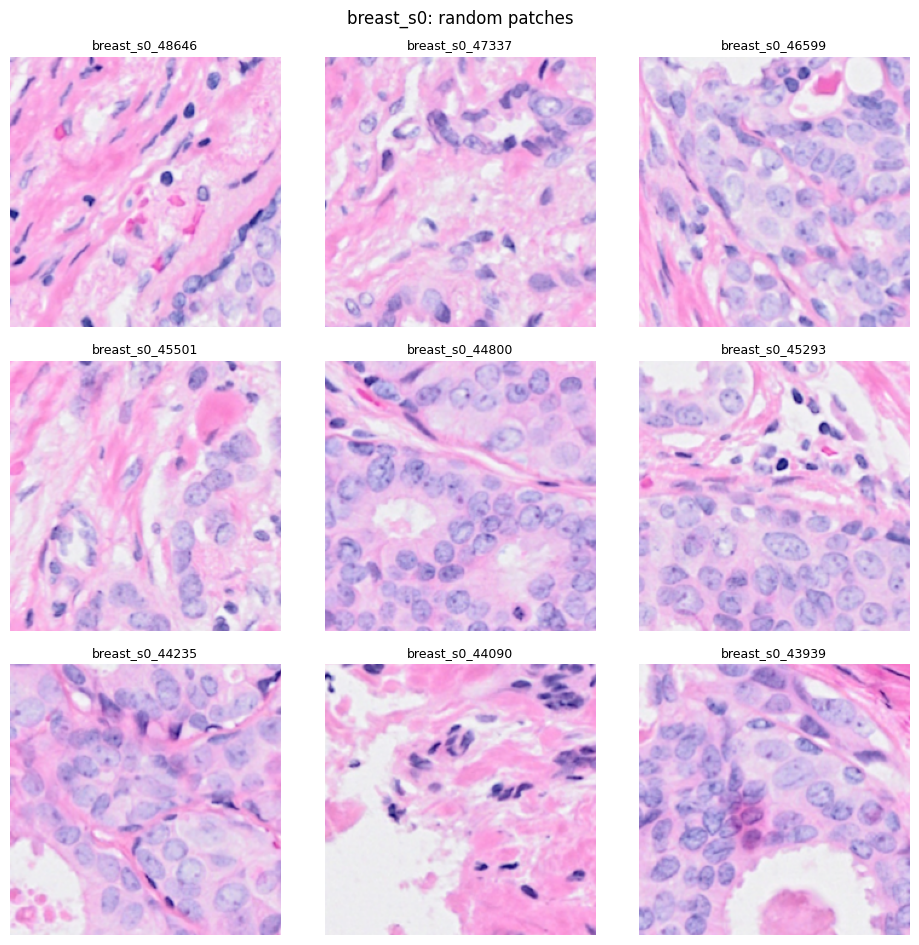

In [4]:
# ---- choose a slide + load + validate ----

# Choose a slide
slide_id = sthelar_slides[0] if len(sthelar_slides) > 0 else hest_slides[0]
print("Chosen slide:", slide_id)

paths = slide_paths(eval_folder, slide_id)
for k, p in paths.items():
    print(f"{k:>10}: {p} (exists={p.exists()})")

# Load .h5 (lazy) and .h5ad
h5obj = HestH5.open(paths["h5"])
adata = read_h5ad(paths["h5ad"])

adata_view = parse_adata_rows(adata, slide_id=slide_id)
print("AnnData summary:")
display(pd.Series(summarize_adata(adata_view)))

# Validate consistency (strict)
report = validate_h5_vs_h5ad(h5obj, adata_view, strict=True)
print("Consistency report:")
display(pd.Series(report))

# Quick patch grid
show_patch_grid(h5obj, n=9, seed=0, title=f"{slide_id}: random patches")

In [5]:
# ---- load membership + training dir for masks ----
# Optional (STHELAR)

found_membership = find_membership_parquets(eval_folder, slide_id)
viz_backbone = None
if not found_membership:
    membership_group = None
    membership_df = None
    print("No membership parquet found for this slide (expected for HEST, or if membership folders were not generated).")
else:
    print("Found membership files:")
    for g, p in found_membership.items():
        print(f"  - {g}: {p}")
    membership_group = choose_default_membership_group(found_membership)
    print("Chosen membership group:", membership_group)
    if membership_group is not None:
        viz_backbone = _GROUP_TO_CFG[membership_group]["default_viz_backbone"]
        print("Visualization backbone for exact image preprocessing:", viz_backbone)
    membership_df = load_membership_parquet(found_membership[membership_group])
    if membership_df is None:
        print("Membership parquet exists but could not be loaded (unexpected).")
    else:
        print("Membership parquet loaded:", membership_df.shape)
        display(membership_df.head())

training_dir = None
if slide_id in sthelar_slides:
    training_dir = get_training_dataset_dir(dataset_id, training_dataset_id)
    print("Training dataset dir (for masks):", training_dir)
    print("Masks zip exists:", (training_dir / "masks_cell_ids_nuclei.zip").exists())

Found membership files:
  - hoptimus0_hoptimus1_uni2h_virchow2: /path/to/ALHENA_data/eval/eval_datasets/st_eval_data/eval_st_ds_ct1_20x_224_o112_1/cell_token_membership_hoptimus0_hoptimus1_uni2h_virchow2/breast_s0.parquet
Chosen membership group: hoptimus0_hoptimus1_uni2h_virchow2
Visualization backbone for exact image preprocessing: hoptimus0
Membership parquet loaded: (1131737, 5)


,cell_id_int,cell_id,patch_id,token_index,nuc_px
0,88090,aaabfibj-1,breast_s0_43870,13,4
1,88090,aaabfibj-1,breast_s0_43870,14,28
2,88091,aaabfibk-1,breast_s0_43870,15,11
3,88093,aaabfibm-1,breast_s0_43870,13,73
4,88093,aaabfibm-1,breast_s0_43870,14,65


Training dataset dir (for masks): /path/to/ALHENA_data/train/training_datasets/ds_ct1_20x_224_o112/ds_ct1_20x_224_o112_1
Masks zip exists: True


Chosen patch_id: breast_s0_43964


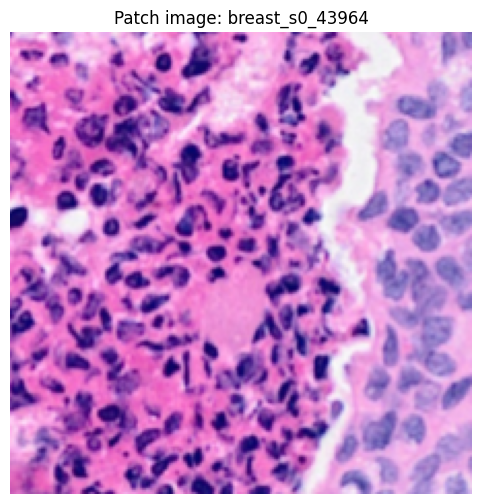

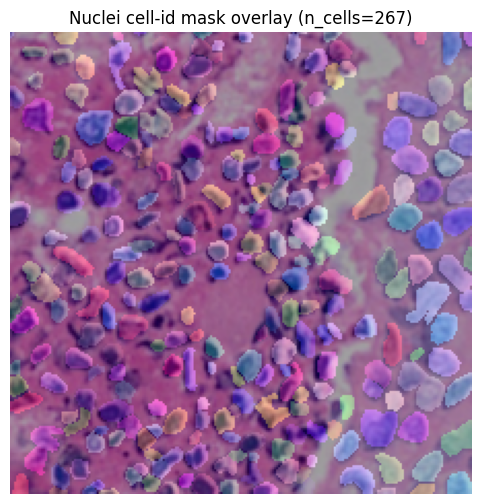

Top cells by nucleus pixels in this patch (mask):


,nuc_px
556427,267
556512,254
558219,229
558217,198
556465,182
556656,181
556671,181
556407,180
556499,172
556432,171


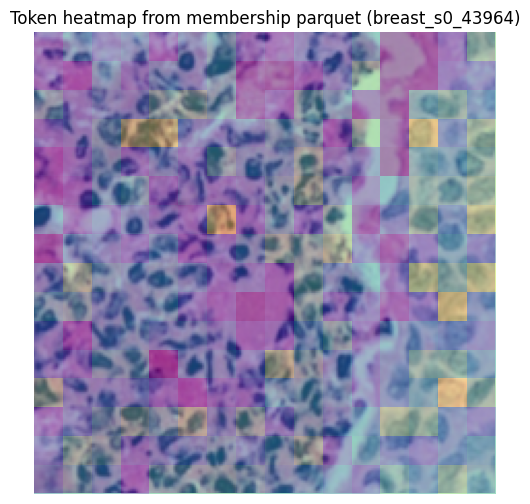

Top tokens by nucleus pixels (membership parquet):


,nuc_px
token_index,
206,176
158,169
61,167
102,164
52,162
143,158
51,157
141,156
111,153


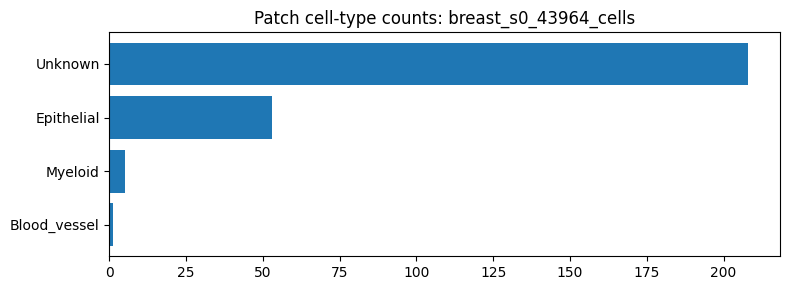

[breast_s0_43964_cells] total_counts=3519.9 | n_expressed_genes=302/380


,count
GATA3,194.805771
TACSTD2,145.771988
MUC1,140.217850
LDHA,135.569031
ANKRD30A,110.358505
CLIC6,108.748283
FLNB,99.018776
FOXA1,97.244469
KRT7,96.499435
TPD52,91.667076


In [6]:
# ---- pick a patch + deep visualization ----

patch_ids = h5obj.get_all_patch_ids()

# Pick a patch with membership rows if available (more informative)
patch_id = None
if membership_df is not None:
    # pick the patch_id with the most membership rows (often richest)
    counts = membership_df["patch_id"].value_counts()
    patch_id = counts.index[0]
else:
    patch_id = patch_ids[0]

print("Chosen patch_id:", patch_id)

show_patch_detail(
    h5obj=h5obj,
    adata_view=adata_view,
    patch_id=patch_id,
    training_dataset_dir=training_dir,    # enables mask overlay if available
    membership_df=membership_df,          # enables token heatmap if available
    membership_group=membership_group,    # makes overlays preprocess-correct
    backbone_for_viz=viz_backbone,        # exact OpenCV interpolation for the chosen backbone
    token_px=14,
)

In [7]:
# ---- strict membership spot-check: parquet vs recomputed from raw mask ----

if (training_dir is None) or (membership_df is None) or (membership_group is None):
    print("Skipping membership spot-check (needs STHELAR masks + membership parquet).")
else:
    try:
        cfg = _GROUP_TO_CFG[membership_group]
        mask = load_nuclei_mask_from_training_zip(training_dir, patch_id=patch_id)

        rep = compare_membership_patch_vs_recomputed(
            membership_df=membership_df,
            patch_id=patch_id,
            mask=mask,
            resize_size=cfg["resize_size"],
            crop_size=cfg["crop_size"],
            token_px=14,
        )
        print("Membership parquet vs recomputed-from-mask spot-check:")
        display(pd.Series(rep))
        print("Interpretation: exact_match should be True. Any mismatch usually means preprocessing drift.")
    except Exception as e:
        print("Membership spot-check failed:", e)

Membership parquet vs recomputed-from-mask spot-check:


n_rows_parquet             649
n_rows_recomputed          649
sum_nuc_px_parquet       21227
sum_nuc_px_recomputed    21227
exact_match               True
n_mismatched_rows            0
max_abs_delta_nuc_px         0
mismatch_examples           []
dtype: object

Interpretation: exact_match should be True. Any mismatch usually means preprocessing drift.


Cell rows: (76139, 15)
   cell_id present: True
cell_id_int present: True
 cell_type present: True


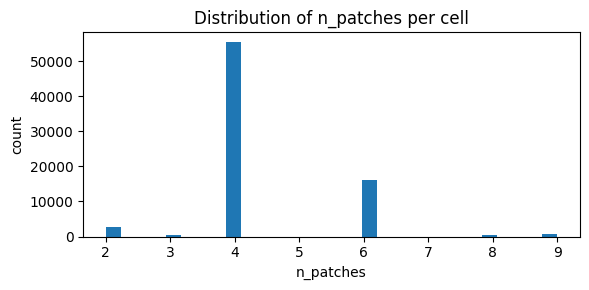

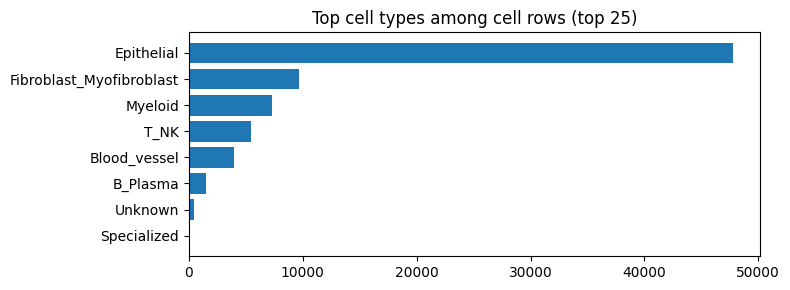

In [8]:
# ---- cell-level sanity plots, if present ----
# Cell-level checks (STHELAR .h5ad should have cell rows)

if len(adata_view.cell_row_names) == 0:
    print("No cell rows detected in this .h5ad (likely HEST).")
else:
    cell_obs = adata.obs.loc[adata_view.cell_row_names].copy()
    print("Cell rows:", cell_obs.shape)

    # Basic required fields
    required = ["cell_id", "cell_id_int", "cell_type"]
    for r in required:
        print(f"{r:>10} present:", r in cell_obs.columns)

    # n_patches distribution (how many patches each cell touches)
    if "n_patches" in cell_obs.columns:
        plt.figure(figsize=(6,3))
        plt.hist(cell_obs["n_patches"].astype(int).values, bins=30)
        plt.title("Distribution of n_patches per cell")
        plt.xlabel("n_patches")
        plt.ylabel("count")
        plt.tight_layout()
        plt.show()

    # cell type distribution
    if "cell_type" in cell_obs.columns:
        ct = cell_obs["cell_type"].value_counts().head(25)
        plt.figure(figsize=(8, max(3, 0.25 * len(ct))))
        plt.barh(ct.index[::-1], ct.values[::-1])
        plt.title("Top cell types among cell rows (top 25)")
        plt.tight_layout()
        plt.show()

In [10]:
# ---- strong STHELAR spot-check — patch expr vs sum(cell expr) ----
# STHELAR spot-check:
# Recompute patch expression from cell rows using the nuclei mask cell IDs
# and compare to the patch '{patch_id}_cells' expression.

if (training_dir is None) or (len(adata_view.cell_row_names) == 0):
    print("Skipping recompute spot-check (needs STHELAR cell rows + training masks).")
else:
    try:
        mask = load_nuclei_mask_from_training_zip(training_dir, patch_id=patch_id)
        patch_row_name = f"{patch_id}_cells" if f"{patch_id}_cells" in adata.obs.index else patch_id

        res = recompute_patch_expr_from_cells(
            adata_view=adata_view,
            slide_id=slide_id,
            cell_id_ints_in_patch=mask,
            patch_row_name=patch_row_name,
            training_dataset_dir=training_dir,
            n_genes_check=80,   # keep moderate
            seed=0,
        )
        print("Recompute patch expr from cell rows (gene-subset check):")
        display(pd.Series(res))
        print("Interpretation: rel_L1/rel_L2 should be close to 0 if patch '_cells' truly equals sum of its member cells (up to any definition quirks).")
    except Exception as e:
        print("Spot-check failed:", e)

Recompute patch expr from cell rows (gene-subset check):


n_cells                                                        267
genes_checked                                                   80
weighting        whole_cell_expr_weighted_by_patch_nucleus_frac...
rel_L1                                                         0.0
rel_L2                                                         0.0
dtype: object

Interpretation: rel_L1/rel_L2 should be close to 0 if patch '_cells' truly equals sum of its member cells (up to any definition quirks).


In [11]:
# Close h5 handle when done
h5obj.close()
print("Closed .h5.")

Closed .h5.
